# Дисциплина: Ad-hoc-аналитика
## Выполнил: Казимиров Егор

## ТЗ по семи вопросам

**Заказчик:** продакт-менеджер Аня

**Проблема:** 20 июля на Android кликабельность top_search резко выросла выше обычного

**Цель:** понять, является ли рост кликабельности реальным эффектом или ошибкой трекинга

**Гипотеза:** рост вызван ошибкой трекинга (например, двойное логирование кликов), а не реальным интересом пользователей

**Метрика:** кликабельность (CTR = клики / показы) и конверсия из клика в отклик (CVR = отклики / клики)

**Период:** июль 2026 (с фокусом на 20 июля)

**Сегменты:** Android (проблемная платформа), а также iOS и WEB для сравнения (контроль)

**Критерий успеха:** если 20 июля на Android CTR аномально высокий, а CVR падает или не растет, то это подтверждает ошибку трекинга

**Решение по результату:** если ошибка трекинга, то нужно починить логирование, а если реальный эффект, то поменять формат показа

## Выбранная ступень глубины

Я выбрал ступень **разбора**. Цена ошибки средняя, потому что если зря поменять формат показа, продукт временно станет хуже для части пользователей. Откатить это можно без следа выключением флага, поэтому глубокий разбор избыточен, прикидки будет также недостаточно, потому что перед ответом заказчику нужно обязательно проверить качество данных и исключить сбой трекинга

## Раздел про качество данных

Сначала я проверяю, можно ли вообще доверять этим данным, вдруг аномалия 20 июля - это не настоящий эффект, а просто ошибка. Здесь я просто запускаю проверку на полные дубли строк и пропуски в ключевых полях, а также смотрю на дубли по самим id событий (impression_id и click_id).

Отдельно я решил поискать клики, у которых нет соответствующего показа, потому что это частая проблема трекинга. Если на Android 20 июля сломался парсинг или клики начали записываться дважды, то это проявится либо в виде дублей click_id, либо в виде кликов без привязки к показам

Сначала нужно подключить нужные библиотеки и загрузить данные из CSV-файлов (библиотеки некоторые подписал для себя, чтобы лучше их запомнить)

In [1]:
import pandas as pd
import duckdb # позволяет писать SQL-запросы прямо тут
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # для красивых графиков
import plotly.graph_objects as go # тоже для графиков, но чтобы можно было навести на него
from IPython.display import display # для красивого вывода таблиц

impressions = pd.read_csv('impressions.csv')
clicks = pd.read_csv('clicks.csv')
responses = pd.read_csv('responses.csv')

# регистрирую CSV как таблицы, чтобы обращаться к ним из SQL
con = duckdb.connect()
con.register("impressions", impressions)
con.register("clicks", clicks)
con.register("responses", responses)

def sql(query: str) -> pd.DataFrame:
    return con.execute(query).df()

Теперь нужно загрузить готовые функции из лекции, чтобы дальше считать метрики и здесь мне конкретно нужны **wilson_ci и proportion_table**, чтобы добавить на график кликабельности доверительные интервалы

In [2]:
from typing import Iterable, Optional, Sequence, Tuple

def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))

def proportion_table(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    success_col: str,
    n_col: str,
    rate_name: str = "rate",
) -> pd.DataFrame:
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g

def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)

def one_pager(
    decision: str, 
    context: str, 
    what_done: str, 
    result: str, 
    limits: str, 
    action: str,
) -> str:
    parts = [
        "ИТОГОВАЯ СПРАВКА",
        "Решение:", decision, "", 
        "Контекст:", context, "",
        "Что сделали:", what_done, "", 
        "Результат:", result, "",
        "Ограничения:", limits, "", 
        "Рекомендованное действие:", action,
    ]
    return "\n".join(parts)

In [3]:
# и смотрю на качество данных
display(summarize_dq(impressions, key_cols=["impression_id"]))
display(summarize_dq(clicks, key_cols=["click_id"]))
orphan_clicks = (~clicks["impression_id"].isin(impressions["impression_id"])).sum()
print("Клики без соответствующего показа:", int(orphan_clicks))

,проверка,значение
0,строк всего,80000
1,полных дублей строк,0
2,пропуски: impression_id,0
3,пропуски: event_date,0
4,пропуски: platform,0
5,пропуски: segment,0
6,пропуски: product,0
7,пропуски: vacancy_id,0
8,пропуски: employer_id,0
9,пропуски: hhuid,0


,проверка,значение
0,строк всего,3837
1,полных дублей строк,0
2,пропуски: click_id,0
3,пропуски: impression_id,0
4,пропуски: event_date,0
5,пропуски: platform,0
6,пропуски: segment,0
7,пропуски: product,0
8,пропуски: vacancy_id,0
9,пропуски: employer_id,0


Клики без соответствующего показа: 0


In [4]:
# я решил проверить 3 дня с самой высокой кликабельностью по платформам
daily = sql('''
SELECT
    i.event_date,
    i.platform,
    COUNT(*) AS impressions,
    SUM(CASE WHEN c.click_id IS NOT NULL THEN 1 ELSE 0 END) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.product = 'top_search'
  AND i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
GROUP BY 1, 2
''')
daily["ctr"] = daily["clicks"] / daily["impressions"]

anomaly_days = daily.sort_values('ctr', ascending=False).groupby('platform').head(3)
print("Топ-3 дня с самой высокой кликабельностью по платформам:")
display(anomaly_days[['platform', 'event_date', 'ctr', 'clicks', 'impressions']])

Топ-3 дня с самой высокой кликабельностью по платформам:


,platform,event_date,ctr,clicks,impressions
65,ANDROID,2026-07-20,0.093995,36.0,383
18,MOBILE_WEB,2026-07-20,0.078818,32.0,406
90,MOBILE_WEB,2026-07-17,0.072464,25.0,345
58,DESKTOP_WEB,2026-07-01,0.070813,74.0,1045
6,DESKTOP_WEB,2026-07-07,0.068996,77.0,1116
19,DESKTOP_WEB,2026-07-17,0.068807,45.0,654
99,MOBILE_WEB,2026-07-07,0.066884,41.0,613
86,IOS,2026-07-24,0.055749,16.0,287
28,IOS,2026-07-25,0.047923,15.0,313
66,IOS,2026-07-03,0.045889,24.0,523


Результаты показали, что данные логирования технически чистые. Дублей нет, пропусков нет, а также нет кликов без соответствующих показов. Это исключает двойное логирование на уровне записи событий. Однако, чтобы понять природу аномалии 20 июля, необходимо посмотреть на метрику CVR.

Дополнительно я проверил справочники значений и увидел, что веб разделен на две платформы: **DESKTOP_WEB** и **MOBILE_WEB**.

## Теперь графики

In [5]:
# сначала нужно собрать показы и клики в одну таблицу для расчета воронки
q_funnel = '''
WITH impr AS (
    SELECT platform, product, COUNT(*) AS impressions
    FROM impressions
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2
),
clk AS (
    SELECT platform, product, COUNT(*) AS clicks
    FROM clicks
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2
)
SELECT
    i.platform,
    i.product,
    i.impressions,
    COALESCE(c.clicks, 0) AS clicks
FROM impr i
LEFT JOIN clk c ON c.platform = i.platform AND c.product = i.product
'''
funnel = sql(q_funnel)

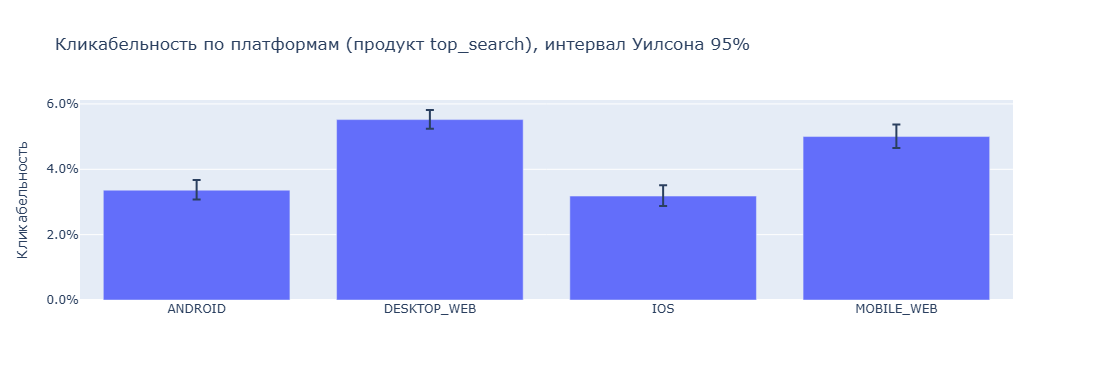

In [6]:
# считаю CTR и сразу добавляю интервал Уилсона, потому что без него непонятно, это реальная разница или 
# шум из-за разного объема данных
funnel_ci = proportion_table(
    funnel.rename(columns={"clicks": "successes", "impressions": "n"}),
    group_cols=["platform", "product"],
    success_col="successes",
    n_col="n",
    rate_name="ctr",
)
funnel_ci = funnel_ci.merge(
    funnel[["platform", "product", "clicks", "impressions"]],
    on=["platform", "product"],
    how="left",
)

plot_df = funnel_ci[funnel_ci["product"] == "top_search"].copy()

fig = go.Figure()
fig.add_trace(go.Bar(
    name="Кликабельность",
    x=plot_df["platform"],
    y=plot_df["ctr"],
    error_y=dict(
        type="data",
        array=plot_df["ci_high"] - plot_df["ctr"],
        arrayminus=plot_df["ctr"] - plot_df["ci_low"],
    ),
))
fig.update_layout(
    title="Кликабельность по платформам (продукт top_search), интервал Уилсона 95%",
    yaxis_tickformat=".1%",
    yaxis_title="Кликабельность",
    height=380,
)
fig.show()

если посмотреть на средние значения за весь июль, то Android не выделяется высокой кликабельностью, он находится на уровне iOS (около 3.5%), в то время как лидирует десктопный веб, это значит, что аномалия 20 июля растворилась по всему месяцу и не видна в общих средних, а чтобы увидеть сам выброс нужно посмотреть на распределение по дням

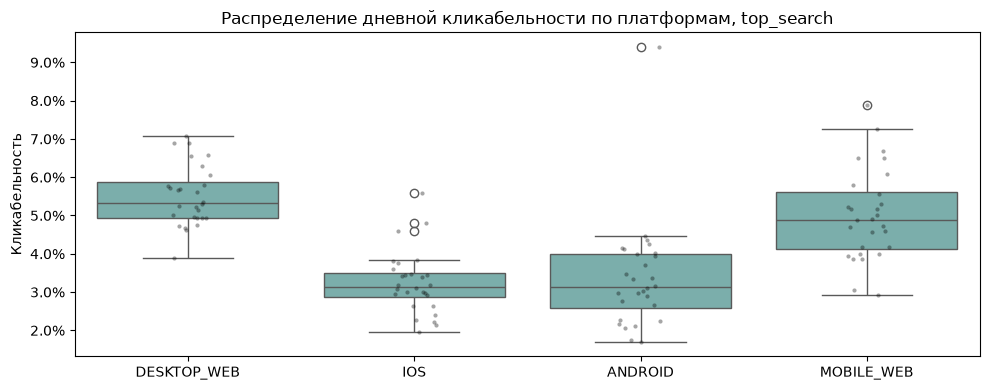

In [7]:
# в этом графике распределение дневной кликабельности, чтобы найти выбросы
daily = sql('''
SELECT
    i.event_date,
    i.platform,
    COUNT(*) AS impressions,
    SUM(CASE WHEN c.click_id IS NOT NULL THEN 1 ELSE 0 END) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.product = 'top_search'
  AND i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
GROUP BY 1, 2
''')
daily["ctr"] = daily["clicks"] / daily["impressions"]

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=daily, x="platform", y="ctr", ax=ax, color="#72B7B2")
sns.stripplot(data=daily, x="platform", y="ctr", ax=ax, color="black", size=3, alpha=0.35)
ax.set_title("Распределение дневной кликабельности по платформам, top_search")
ax.set_ylabel("Кликабельность")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
plt.tight_layout()
plt.show()

на распределении четко виден аномальный выброс на Android, одна точка улетела почти к 9.5%, тогда как основная масса дней держится в районе 2.5–4.5%. Это подтверждает, что 20 июля на Android действительно был зафиксирован аномальный рост кликабельности, который резко выбивается за пределы обычного разброса значений

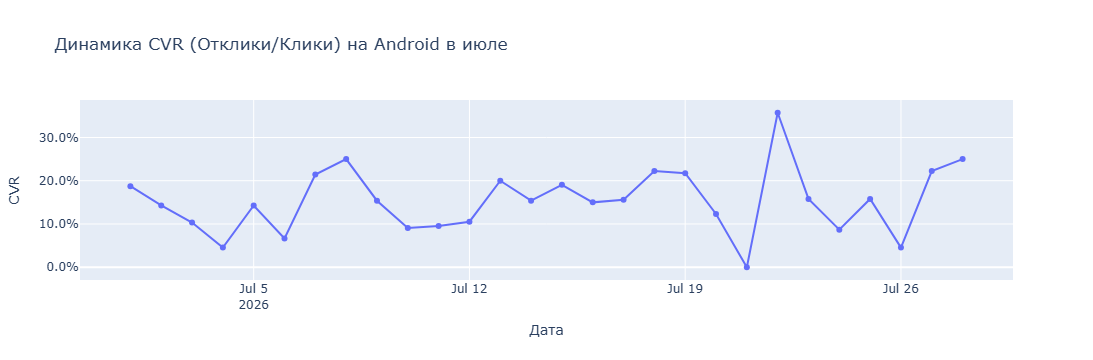

In [8]:
# считаю клики по дням для Android
q_clicks_android = '''
SELECT event_date, COUNT(*) AS clicks
FROM clicks
WHERE platform = 'ANDROID' AND year = '2026' AND month = '07'
GROUP BY 1
'''
clicks_android = sql(q_clicks_android)

# считаю отклики по дням для Android
q_responses_android = '''
SELECT event_date, COUNT(*) AS responses
FROM responses
WHERE platform = 'ANDROID' AND year = '2026' AND month = '07'
GROUP BY 1
'''
responses_android = sql(q_responses_android)

cvr_df = pd.merge(clicks_android, responses_android, on='event_date', how='left').fillna(0)
cvr_df['responses'] = cvr_df['responses'].astype(float)
cvr_df['clicks'] = cvr_df['clicks'].astype(float)

# считаю CVR 
cvr_df['cvr'] = cvr_df.apply(lambda row: row['responses'] / row['clicks'] if row['clicks'] > 0 else None, axis=1)

cvr_df['event_date'] = pd.to_datetime(cvr_df['event_date'])
cvr_df = cvr_df.sort_values('event_date')

fig = go.Figure()
fig.add_trace(go.Scatter(x=cvr_df['event_date'], y=cvr_df['cvr'], mode='lines+markers', name='CVR (Android)'))

fig.update_layout(
    title="Динамика CVR (Отклики/Клики) на Android в июле",
    xaxis_title="Дата",
    yaxis_title="CVR",
    yaxis_tickformat='.1%',
    hovermode="x unified"
)
fig.show()

Наглядное падение CVR 20–21 июля подтверждает аномальный характер кликов

## Итоговый вывод

In [9]:
print(
    one_pager(
        decision="Подтверждена ошибка трекинга. Не менять формат показа. Требуется вмешательство технической команды для очистки логов",
        context="20 июля на Android кликабельность top_search резко выросла. Нужно было понять, является ли это реальным эффектом или ошибкой",
        what_done="Проверил дубли, пропуски и клики без показов, построил графики CTR с интервалом, проанализировал топ-3 аномальных дня, а также рассчитал метрику CVR",
        result="Данные логирования технически чистые, но 20 июля на Android CTR выбился до 9%. При этом проверка метрики CVR показала аномалию, что 20 июля CVR снизился до 12% (на фоне обычных 15-20%), а 21 июля рухнул до 0%. Это подтверждает наплыв мусорных кликов в эти дни",
        limits="Не проверял логи, не искал конкретные IP-адреса и устройства, с которых шли подозрительные клики",
        action="1) Передать задачу инженерам для проверки логов 20-21 июля на Android; 2) Внедрить антифрод-фильтры для отсечения кликов без последующих действий; 3) Не менять формат показа, так как реальный интерес пользователей не подтвержден",
    )
)

ИТОГОВАЯ СПРАВКА
Решение:
Подтверждена ошибка трекинга. Не менять формат показа. Требуется вмешательство технической команды для очистки логов

Контекст:
20 июля на Android кликабельность top_search резко выросла. Нужно было понять, является ли это реальным эффектом или ошибкой

Что сделали:
Проверил дубли, пропуски и клики без показов, построил графики CTR с интервалом, проанализировал топ-3 аномальных дня, а также рассчитал метрику CVR

Результат:
Данные логирования технически чистые, но 20 июля на Android CTR выбился до 9%. При этом проверка метрики CVR показала аномалию, что 20 июля CVR снизился до 12% (на фоне обычных 15-20%), а 21 июля рухнул до 0%. Это подтверждает наплыв мусорных кликов в эти дни

Ограничения:
Не проверял логи, не искал конкретные IP-адреса и устройства, с которых шли подозрительные клики

Рекомендованное действие:
1) Передать задачу инженерам для проверки логов 20-21 июля на Android; 2) Внедрить антифрод-фильтры для отсечения кликов без последующих действий; 3